# Lecture 1: Kernel Density Estimation, Interpolation & Linear Least-Squares Fitting

Introduce the main computational concepts and develop the mathematical foundations of the numerical methods, explaining how they are derived and the ideas behind them.


## Part A and Part B — Theory and Numerical Methods and Guided Implementation

The following topics are developed through theory and guided examples:

### 1. Kernel Density Estimation

1. Histograms and density estimation

2. Kernel functions and bandwidth selection

3. Density fitting with `KernelDensity` and cross-validation

### 2. Interpolation and Linear Least-Squares Fitting

1. Polynomial interpolation and Runge's phenomenon

2. Piecewise interpolation and splines

3. Linear models, design matrices, and least-squares fitting

4. Applications to computational-physics data


In the previous chapter we covered Gaussian mixture models, which are a kind of hybrid between a clustering estimator and a density estimator.
Recall that a density estimator is an algorithm that takes a $D$-dimensional dataset and produces an estimate of the $D$-dimensional probability distribution that data is drawn from.
The GMM algorithm accomplishes this by representing the density as a weighted sum of Gaussian distributions.
*Kernel density estimation* (KDE) is in some senses an algorithm that takes the mixture-of-Gaussians idea to its logical extreme: it uses a mixture consisting of one Gaussian component *per point*, resulting in an essentially nonparametric estimator of density.
In this chapter, we will explore the motivation and uses of KDE.

We begin with the standard imports:

# In Depth: Kernel Density Estimation

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-whitegrid')
import numpy as np

## Motivating Kernel Density Estimation: Histograms

As mentioned previously, a density estimator is an algorithm that seeks to model the probability distribution that generated a dataset.
For one-dimensional data, you are probably already familiar with one simple density estimator: the histogram.
A histogram divides the data into discrete bins, counts the number of points that fall in each bin, and then visualizes the results in an intuitive manner.

For example, let's create some data that is drawn from two normal distributions:

In [ ]:
def make_data(N, f=0.3, rseed=1):
    rand = np.random.RandomState(rseed)
    x = rand.randn(N)
    x[int(f * N):] += 5
    return x

x = make_data(1000)

We have previously seen that the standard count-based histogram can be created with the `plt.hist` function.
By specifying the `density` parameter of the histogram, we end up with a normalized histogram where the height of the bins does not reflect counts, but instead reflects probability density (see the following figure):

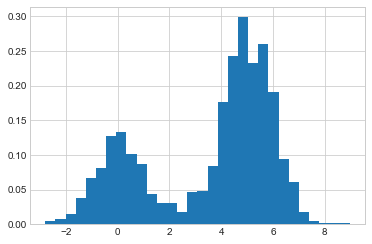

In [ ]:
hist = plt.hist(x, bins=30, density=True)

Notice that for equal binning, this normalization simply changes the scale on the y-axis, leaving the relative heights essentially the same as in a histogram built from counts.
This normalization is chosen so that the total area under the histogram is equal to 1, as we can confirm by looking at the output of the histogram function:

In [ ]:
density, bins, patches = hist
widths = bins[1:] - bins[:-1]
(density * widths).sum()

1.0

One of the issues with using a histogram as a density estimator is that the choice of bin size and location can lead to representations that have qualitatively different features.
For example, if we look at a version of this data with only 20 points, the choice of how to draw the bins can lead to an entirely different interpretation of the data!
Consider this example, visualized in the following figure:

In [ ]:
x = make_data(20)
bins = np.linspace(-5, 10, 10)

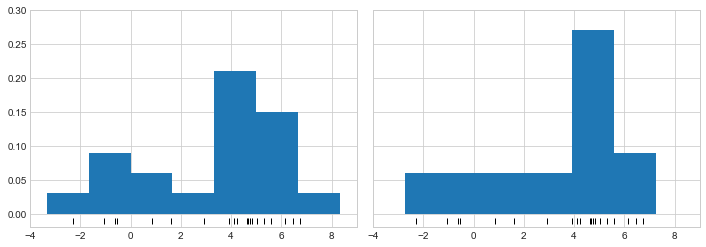

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4),
                       sharex=True, sharey=True,
                       subplot_kw={'xlim':(-4, 9),
                                   'ylim':(-0.02, 0.3)})
fig.subplots_adjust(wspace=0.05)
for i, offset in enumerate([0.0, 0.6]):
    ax[i].hist(x, bins=bins + offset, density=True)
    ax[i].plot(x, np.full_like(x, -0.01), '|k',
               markeredgewidth=1)

On the left, the histogram makes clear that this is a bimodal distribution.
On the right, we see a unimodal distribution with a long tail.
Without seeing the preceding code, you would probably not guess that these two histograms were built from the same data. With that in mind, how can you trust the intuition that histograms confer?
And how might we improve on this?

Stepping back, we can think of a histogram as a stack of blocks, where we stack one block within each bin on top of each point in the dataset.
Let's view this directly (see the following figure):

(-0.2, 8.0)

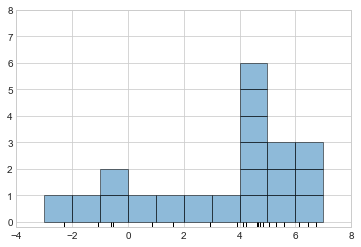

In [ ]:
fig, ax = plt.subplots()
bins = np.arange(-3, 8)
ax.plot(x, np.full_like(x, -0.1), '|k',
        markeredgewidth=1)
for count, edge in zip(*np.histogram(x, bins)):
    for i in range(count):
        ax.add_patch(plt.Rectangle(
            (edge, i), 1, 1, ec='black', alpha=0.5))
ax.set_xlim(-4, 8)
ax.set_ylim(-0.2, 8)

The problem with our two binnings stems from the fact that the height of the block stack often reflects not the actual density of points nearby, but coincidences of how the bins align with the data points.
This misalignment between points and their blocks is a potential cause of the poor histogram results seen here.
But what if, instead of stacking the blocks aligned with the *bins*, we were to stack the blocks aligned with the *points they represent*?
If we do this, the blocks won't be aligned, but we can add their contributions at each location along the x-axis to find the result.
Let's try this (see the following figure):

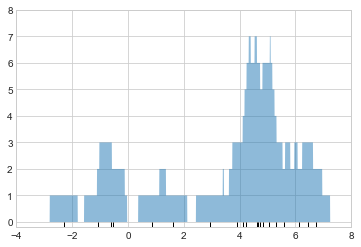

In [ ]:
x_d = np.linspace(-4, 8, 2000)
density = sum((abs(xi - x_d) < 0.5) for xi in x)

plt.fill_between(x_d, density, alpha=0.5)
plt.plot(x, np.full_like(x, -0.1), '|k', markeredgewidth=1)

plt.axis([-4, 8, -0.2, 8]);

The result looks a bit messy, but it's a much more robust reflection of the actual data characteristics than is the standard histogram.
Still, the rough edges are not aesthetically pleasing, nor are they reflective of any true properties of the data.
In order to smooth them out, we might decide to replace the blocks at each location with a smooth function, like a Gaussian.
Let's use a standard normal curve at each point instead of a block (see the following figure):

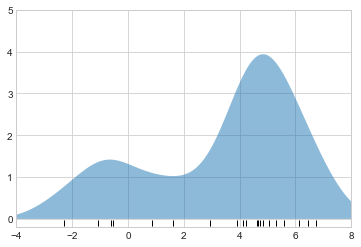

In [ ]:
from scipy.stats import norm
x_d = np.linspace(-4, 8, 1000)
density = sum(norm(xi).pdf(x_d) for xi in x)

plt.fill_between(x_d, density, alpha=0.5)
plt.plot(x, np.full_like(x, -0.1), '|k', markeredgewidth=1)

plt.axis([-4, 8, -0.2, 5]);

This smoothed-out plot, with a Gaussian distribution contributed at the location of each input point, gives a much more accurate idea of the shape of the data distribution, and one that has much less variance (i.e., changes much less in response to differences in sampling).

What we've landed on in the last two plots is what's called kernel density estimation in one dimension: we have placed a "kernel"—a square or "tophat"-shaped kernel in the former, a Gaussian kernel in the latter—at the location of each point, and used their sum as an estimate of density.
With this intuition in mind, we'll now explore kernel density estimation in more detail.

## Kernel Density Estimation in Practice

The free parameters of kernel density estimation are the *kernel*, which specifies the shape of the distribution placed at each point, and the *kernel bandwidth*, which controls the size of the kernel at each point.
In practice, there are many kernels you might use for kernel density estimation: in particular, the Scikit-Learn KDE implementation supports six kernels, which you can read about in the ["Density Estimation" section](http://scikit-learn.org/stable/modules/density.html) of the documentation.

While there are several versions of KDE implemented in Python (notably in the SciPy and `statsmodels` packages), I prefer to use Scikit-Learn's version because of its efficiency and flexibility.
It is implemented in the `sklearn.neighbors.KernelDensity` estimator, which handles KDE in multiple dimensions with one of six kernels and one of a couple dozen distance metrics.
Because KDE can be fairly computationally intensive, the Scikit-Learn estimator uses a tree-based algorithm under the hood and can trade off computation time for accuracy using the `atol` (absolute tolerance) and `rtol` (relative tolerance) parameters.
The kernel bandwidth can be determined using Scikit-Learn's standard cross-validation tools, as we will soon see.

Let's first show a simple example of replicating the previous plot using the Scikit-Learn `KernelDensity` estimator (see the following figure):

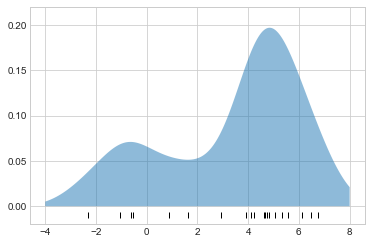

In [ ]:
from sklearn.neighbors import KernelDensity

# instantiate and fit the KDE model
kde = KernelDensity(bandwidth=1.0, kernel='gaussian')
kde.fit(x[:, None])

# score_samples returns the log of the probability density
logprob = kde.score_samples(x_d[:, None])

plt.fill_between(x_d, np.exp(logprob), alpha=0.5)
plt.plot(x, np.full_like(x, -0.01), '|k', markeredgewidth=1)
plt.ylim(-0.02, 0.22);

The result here is normalized such that the area under the curve is equal to 1.

## Selecting the Bandwidth via Cross-Validation

The final estimate produced by a KDE procedure can be quite sensitive to the choice of bandwidth, which is the knob that controls the bias–variance trade-off in the estimate of density.
Too narrow a bandwidth leads to a high-variance estimate (i.e., overfitting), where the presence or absence of a single point makes a large difference. Too wide a bandwidth leads to a high-bias estimate (i.e., underfitting), where the structure in the data is washed out by the wide kernel.

There is a long history in statistics of methods to quickly estimate the best bandwidth based on rather stringent assumptions about the data: if you look up the KDE implementations in the SciPy and `statsmodels` packages, for example, you will see implementations based on some of these rules.

In machine learning contexts, we've seen that such hyperparameter tuning often is done empirically via a cross-validation approach.
With this in mind, Scikit-Learn's `KernelDensity` estimator is designed such that it can be used directly within the package's standard grid search tools.
Here we will use `GridSearchCV` to optimize the bandwidth for the preceding dataset.
Because we are looking at such a small dataset, we will use leave-one-out cross-validation, which minimizes the reduction in training set size for each cross-validation trial:

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import LeaveOneOut

bandwidths = 10 ** np.linspace(-1, 1, 100)
grid = GridSearchCV(KernelDensity(kernel='gaussian'),
                    {'bandwidth': bandwidths},
                    cv=LeaveOneOut())
grid.fit(x[:, None]);

Now we can find the choice of bandwidth that maximizes the score (which in this case defaults to the log-likelihood):

In [ ]:
grid.best_params_

{'bandwidth': 1.1233240329780276}

The optimal bandwidth happens to be very close to what we used in the example plot earlier, where the bandwidth was 1.0 (i.e., the default width of `scipy.stats.norm`).

## Example: Not-so-Naive Bayes

This example looks at Bayesian generative classification with KDE, and demonstrates how to use the Scikit-Learn architecture to create a custom estimator.

In [In Depth: Naive Bayes Classification](05.05-Naive-Bayes.ipynb) we explored naive Bayesian classification, in which we create a simple generative model for each class, and use these models to build a fast classifier.
For Gaussian naive Bayes, the generative model is a simple axis-aligned Gaussian.
With a density estimation algorithm like KDE, we can remove the "naive" element and perform the same classification with a more sophisticated generative model for each class.
It's still Bayesian classification, but it's no longer naive.

The general approach for generative classification is this:

1. Split the training data by label.

2. For each set, fit a KDE to obtain a generative model of the data.
   This allows you, for any observation $x$ and label $y$, to compute a likelihood $P(x~|~y)$.
   
3. From the number of examples of each class in the training set, compute the *class prior*, $P(y)$.

4. For an unknown point $x$, the posterior probability for each class is $P(y~|~x) \propto P(x~|~y)P(y)$.
   The class that maximizes this posterior is the label assigned to the point.

The algorithm is straightforward and intuitive to understand; the more difficult piece is couching it within the Scikit-Learn framework in order to make use of the grid search and cross-validation architecture.

This is the code that implements the algorithm within the Scikit-Learn framework; we will step through it following the code block:

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin


class KDEClassifier(BaseEstimator, ClassifierMixin):
    """Bayesian generative classification based on KDE

    Parameters
    ----------
    bandwidth : float
        the kernel bandwidth within each class
    kernel : str
        the kernel name, passed to KernelDensity
    """
    def __init__(self, bandwidth=1.0, kernel='gaussian'):
        self.bandwidth = bandwidth
        self.kernel = kernel

    def fit(self, X, y):
        self.classes_ = np.sort(np.unique(y))
        training_sets = [X[y == yi] for yi in self.classes_]
        self.models_ = [KernelDensity(bandwidth=self.bandwidth,
                                      kernel=self.kernel).fit(Xi)
                        for Xi in training_sets]
        self.logpriors_ = [np.log(Xi.shape[0] / X.shape[0])
                           for Xi in training_sets]
        return self

    def predict_proba(self, X):
        logprobs = np.array([model.score_samples(X)
                             for model in self.models_]).T
        result = np.exp(logprobs + self.logpriors_)
        return result / result.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), 1)]

### Anatomy of a Custom Estimator

Let's step through this code and discuss the essential features:

```python
from sklearn.base import BaseEstimator, ClassifierMixin

class KDEClassifier(BaseEstimator, ClassifierMixin):
    """Bayesian generative classification based on KDE
    
    Parameters
    ----------
    bandwidth : float
        the kernel bandwidth within each class
    kernel : str
        the kernel name, passed to KernelDensity
    """
```

Each estimator in Scikit-Learn is a class, and it is most convenient for this class to inherit from the `BaseEstimator` class as well as the appropriate mixin, which provides standard functionality.
For example, here the `BaseEstimator` contains (among other things) the logic necessary to clone/copy an estimator for use in a cross-validation procedure, and `ClassifierMixin` defines a default `score` method used by such routines.
We also provide a docstring, which will be captured by IPython's help functionality (see [Help and Documentation in IPython](01.01-Help-And-Documentation.ipynb)).

Next comes the class initialization method:

```python
    def __init__(self, bandwidth=1.0, kernel='gaussian'):
        self.bandwidth = bandwidth
        self.kernel = kernel
```

This is the actual code that is executed when the object is instantiated with `KDEClassifier`.
In Scikit-Learn, it is important that *initialization contains no operations* other than assigning the passed values by name to `self`.
This is due to the logic contained in `BaseEstimator` required for cloning and modifying estimators for cross-validation, grid search, and other functions.
Similarly, all arguments to `__init__` should be explicit: i.e., `*args` or `**kwargs` should be avoided, as they will not be correctly handled within cross-validation routines.

Next comes the `fit` method, where we handle training data:

```python
    def fit(self, X, y):
        self.classes_ = np.sort(np.unique(y))
        training_sets = [X[y == yi] for yi in self.classes_]
        self.models_ = [KernelDensity(bandwidth=self.bandwidth,
                                      kernel=self.kernel).fit(Xi)
                        for Xi in training_sets]
        self.logpriors_ = [np.log(Xi.shape[0] / X.shape[0])
                           for Xi in training_sets]
        return self
```

Here we find the unique classes in the training data, train a `KernelDensity` model for each class, and compute the class priors based on the number of input samples.
Finally, `fit` should always return `self` so that we can chain commands. For example:
```python
label = model.fit(X, y).predict(X)
```
Notice that each persistent result of the fit is stored with a trailing underscore (e.g., `self.logpriors_`).
This is a convention used in Scikit-Learn so that you can quickly scan the members of an estimator (using IPython's tab completion) and see exactly which members are fit to training data.

Finally, we have the logic for predicting labels on new data:
```python
    def predict_proba(self, X):
        logprobs = np.vstack([model.score_samples(X)
                              for model in self.models_]).T
        result = np.exp(logprobs + self.logpriors_)
        return result / result.sum(axis=1, keepdims=True)
        
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), 1)]
```
Because this is a probabilistic classifier, we first implement `predict_proba`, which returns an array of class probabilities of shape `[n_samples, n_classes]`.
Entry `[i, j]` of this array is the posterior probability that sample `i` is a member of class `j`, computed by multiplying the likelihood by the class prior and normalizing.

The `predict` method uses these probabilities and simply returns the class with the largest probability.

### Using Our Custom Estimator

Let's try this custom estimator on a problem we have seen before: the classification of handwritten digits.
Here we will load the digits and compute the cross-validation score for a range of candidate bandwidths using the ``GridSearchCV`` meta-estimator (refer back to [Hyperparameters and Model Validation](05.03-Hyperparameters-and-Model-Validation.ipynb)):

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV

digits = load_digits()

grid = GridSearchCV(KDEClassifier(),
                    {'bandwidth': np.logspace(0, 2, 100)})
grid.fit(digits.data, digits.target);

Next we can plot the cross-validation score as a function of bandwidth (see the following figure):

best param: {'bandwidth': 6.135907273413174}
accuracy = 0.9677298050139276


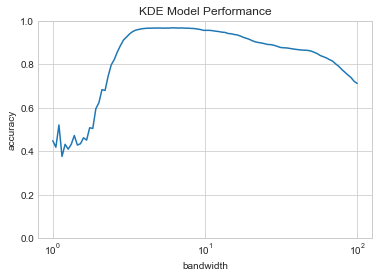

In [ ]:
fig, ax = plt.subplots()
ax.semilogx(np.array(grid.cv_results_['param_bandwidth']),
            grid.cv_results_['mean_test_score'])
ax.set(title='KDE Model Performance', ylim=(0, 1),
       xlabel='bandwidth', ylabel='accuracy')
print(f'best param: {grid.best_params_}')
print(f'accuracy = {grid.best_score_}')

This indicates that our KDE classifier reaches a cross-validation accuracy of over 96%, compared to around 80% for the naive Bayes classifier:

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
cross_val_score(GaussianNB(), digits.data, digits.target).mean()

0.8069281956050759

One benefit of such a generative classifier is interpretability of results: for each unknown sample, we not only get a probabilistic classification, but a *full model* of the distribution of points we are comparing it to!
If desired, this offers an intuitive window into the reasons for a particular classification that algorithms like SVMs and random forests tend to obscure.

If you would like to take this further, here are some ideas for improvements that could be made to our KDE classifier model:

- You could allow the bandwidth in each class to vary independently.
- You could optimize these bandwidths not based on their prediction score, but on the likelihood of the training data under the generative model within each class (i.e. use the scores from `KernelDensity` itself rather than the global prediction accuracy).

Finally, if you want some practice building your own estimator, you might tackle building a similar Bayesian classifier using Gaussian mixture models instead of KDE.

## 1. Interpolation & Linear Least-Squares Fitting

## Experimental Data Analysis

Every physics experiment produces a finite set of noisy, discrete measurements $(x_i, y_i)$. Turning that
table of numbers into physical understanding requires answering one of two very different questions:

1. **"What is the value between my measurements?"** — you trust the data points exactly, and you want a
   smooth curve that passes through every one of them. This is **interpolation**.
2. **"What is the underlying physical law, and what are its parameters?"** — you know (or suspect) the
   *noise* is real, and you want the smooth model that best explains the *trend*, not a curve that chases
   every wiggle. This is **curve fitting**.

This lecture builds both skills using only `numpy` and `scipy` (every fit
here is done with the same linear-algebra machinery you already used to solve circuits in
`3.CoupledSystems`).

### Interpolation

### The temptation: fit one big polynomial through everything

If you have $n+1$ data points, you can *always* find a degree-$n$ polynomial that passes through every one
of them exactly (this is the same "one polynomial to hit every point" idea behind fitting a parabola through
3 points, extended to more points and points). It sounds like the natural thing to do. It is usually a
terrible idea.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# A smooth, well-behaved function...
def f_true(x):
    return 1.0 / (1.0 + 25 * x**2)   # Runge's function

x_nodes = np.linspace(-1, 1, 15)
y_nodes = f_true(x_nodes)

# ...fit a single degree-14 polynomial through all 15 points
coeffs = np.polyfit(x_nodes, y_nodes, deg=14)
poly_interp = np.poly1d(coeffs)

x_dense = np.linspace(-1, 1, 400)

plt.figure(figsize=(7, 4.5))
plt.plot(x_dense, f_true(x_dense), 'k-', label='True function')
plt.plot(x_dense, poly_interp(x_dense), 'r--', label='Degree-14 polynomial through all points')
plt.plot(x_nodes, y_nodes, 'o', color='k', label='Data points')
plt.ylim(-1, 2)
plt.xlabel('x'); plt.ylabel('y')
plt.title("Runge's phenomenon: high-degree interpolation goes wild near the edges")
plt.legend()
plt.show()


This is **Runge's phenomenon**: a single high-degree polynomial forced through many points develops huge,
unphysical oscillations, especially near the edges of the data — even though every individual point is fit
*exactly*. The image below shows the same effect on a different function, with the wiggles clearly visible
between the (exactly-interpolated) data points.

The fix is to give up on a *single* polynomial and instead use many *low-degree* polynomial pieces, one
between each pair of neighboring points, and stitch them together smoothly. This is a **spline**.

In [ ]:
# The same effect on a different function, on a wider interval. Both curves
# below pass *exactly* through their own data points -- these are genuine
# interpolants, not least-squares fits.
def f_lorentz(x):
    return 1.0 / (1.0 + x**2)

x_dense_L = np.linspace(-5, 5, 600)

plt.figure(figsize=(7.2, 4.6))
plt.plot(x_dense_L, f_lorentz(x_dense_L), 'k-', lw=2.2,
         label='True function $1/(1+x^2)$', zorder=5)
for n_nodes, style, col in [(9, '--', 'tab:orange'), (15, '-.', 'tab:red')]:
    xn = np.linspace(-5, 5, n_nodes)
    poly = np.poly1d(np.polyfit(xn, f_lorentz(xn), n_nodes - 1))
    plt.plot(x_dense_L, poly(x_dense_L), style, color=col, lw=1.7,
             label=f'Degree-{n_nodes - 1} through {n_nodes} points')
    plt.plot(xn, f_lorentz(xn), 'o', color=col, ms=5, zorder=6)

plt.ylim(-0.6, 1.7); plt.xlabel('x'); plt.ylabel('y')
plt.title("Runge's phenomenon again -- and adding points makes it *worse*")
plt.legend(fontsize=9, loc='upper right'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Splines: piecewise polynomials, stitched smoothly

A cubic spline $S(x)$ is built from a cubic polynomial $S_i(x) = a_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$
on each interval $[x_i, x_{i+1}]$, with the pieces required to:

1. **Match the data**: $S_i(x_i) = y_i$ for every node.
2. **Join smoothly**: the value, first derivative, *and* second derivative of neighboring pieces agree at
   each shared node (no kinks, no sudden change in curvature).

Condition (2) is what makes a spline different from just drawing $n$ independent parabolas — physically, if
your data represents something like a particle's smooth trajectory, you *want* the interpolant's velocity and
acceleration to be continuous too, not just its position.

In [ ]:
time = np.array([0, 5, 10, 15, 20])
temperature = np.array([20, 23, 27, 33, 40])

f_linear = interp1d(time, temperature, kind='linear')
f_cubic = interp1d(time, temperature, kind='cubic')
cs = CubicSpline(time, temperature)

time_dense = np.linspace(0, 20, 200)

plt.figure(figsize=(7, 4.5))
plt.plot(time, temperature, 'ko', label='Measured data', zorder=5)
plt.plot(time_dense, f_linear(time_dense), '--', label='Linear (interp1d)')
plt.plot(time_dense, f_cubic(time_dense), '-', label='Cubic (interp1d)')
plt.plot(time_dense, cs(time_dense), ':', label='Cubic (CubicSpline)', linewidth=3)
plt.xlabel('Time (minutes)'); plt.ylabel('Temperature (°C)')
plt.title('Interpolating a temperature measurement')
plt.legend()
plt.show()


`scipy.interpolate.interp1d(x, y, kind=...)` and `scipy.interpolate.CubicSpline(x, y)` both return a
**callable** — an actual Python function you can evaluate at any new `x` value inside the original range.
`interp1d` supports `kind='linear'`, `'nearest'`, `'quadratic'`, `'cubic'`, among others; `CubicSpline` is a
dedicated, slightly more modern cubic-spline implementation with the same idea. Both agree closely above,
as they should — they're solving the same well-posed problem.

### ⚛️ Physics Application: recovering a force from a tabulated potential

Suppose a simulation or an experiment hands you the potential energy $U(x)$ of a particle only at a handful
of separations — not as a formula, but as a table (this is exactly how tabulated interatomic potentials are
often distributed in molecular dynamics). You need the **force**, $F(x) = -\dfrac{dU}{dx}$, at *arbitrary*
$x$, not just at the tabulated points.

The strategy: interpolate $U(x)$ with a cubic spline to get a smooth, differentiable stand-in for the
potential, then apply the central-difference numerical derivative from `2.Kinematics` to that spline (or use
its built-in derivative). We'll check the result against a Morse potential, whose force we *do* know in
closed form, so we can judge the interpolation's accuracy honestly.

In [ ]:
def morse_potential(x, De=5.0, a=1.2, xe=1.0):
    return De * (1 - np.exp(-a * (x - xe)))**2 - De

def morse_force_exact(x, De=5.0, a=1.2, xe=1.0):
    # F = -dU/dx, computed analytically for comparison
    return -2 * De * a * (1 - np.exp(-a * (x - xe))) * np.exp(-a * (x - xe))

# Only a sparse table of (x, U) is "measured"
x_table = np.linspace(0.5, 3.5, 9)
U_table = morse_potential(x_table)

U_spline = CubicSpline(x_table, U_table)

x_fine = np.linspace(0.6, 3.4, 300)
# Differentiate the spline analytically (CubicSpline objects support this directly)
F_from_spline = -U_spline(x_fine, 1)     # 1st derivative of the spline, negated
F_exact = morse_force_exact(x_fine)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(x_table, U_table, 'ko', label='Tabulated U(x)')
axes[0].plot(x_fine, U_spline(x_fine), 'b-', label='Cubic spline')
axes[0].set_xlabel('x'); axes[0].set_ylabel('U(x)'); axes[0].legend()
axes[0].set_title('Interpolated potential energy')

axes[1].plot(x_fine, F_exact, 'k-', label='Exact force (Morse)')
axes[1].plot(x_fine, F_from_spline, 'r--', label='F = -dU/dx from spline')
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x)'); axes[1].legend()
axes[1].set_title('Force recovered from the interpolated table')
plt.tight_layout()
plt.show()

max_err = np.max(np.abs(F_from_spline - F_exact))
print(f"Max force error from only {len(x_table)} tabulated points: {max_err:.4f}")


Only 9 tabulated energies were enough to recover the force curve to good accuracy — this is the everyday
payoff of interpolation in computational physics: it lets you work with *sparse, expensive-to-generate* data
(experimental measurements, or an expensive quantum-chemistry calculation) as if you had a smooth function you
could evaluate and differentiate anywhere. The single worst point is near the left edge of the table, not in
the interior — the same boundary effect you saw with `np.gradient` in `6.ElectricAndMagneticFields`: a spline
(like a finite difference) has less neighboring information to work with near the ends of the data, so its
derivative is least trustworthy there. Away from the boundary, the error is many times smaller.

### Curve Fitting

Interpolation was built on trusting every data point exactly. Real experimental data is noisy — trusting it
exactly is exactly the wrong thing to do. Watch what happens if we interpolate noisy data instead of fitting
it.

In [ ]:
np.random.seed(0)
x_noisy = np.linspace(0, 10, 12)
y_noisy = 2.0 * x_noisy + 3.0 + np.random.normal(scale=3.0, size=len(x_noisy))

f_noisy_cubic = interp1d(x_noisy, y_noisy, kind='cubic')
x_fine = np.linspace(0, 10, 300)

plt.figure(figsize=(7, 4.5))
plt.plot(x_noisy, y_noisy, 'ko', label='Noisy data')
plt.plot(x_fine, f_noisy_cubic(x_fine), 'r-', label='Cubic interpolation (forced through every point)')
plt.plot(x_fine, 2.0 * x_fine + 3.0, 'g--', label='True underlying line')
plt.legend()
plt.title('Interpolation amplifies noise instead of averaging it out')
plt.show()


The interpolant chases every noisy wiggle, producing a curve that is *worse* than a straight line at
representing the true underlying trend. What we want instead is a **model** — a physically motivated
functional form with a handful of free parameters — and the *best* choice of those parameters, in the sense
of minimizing the total mismatch with the data. That is curve fitting.

### Least-squares: minimizing the total squared residual

For a model $y = g(x; \mathbf{p})$ with parameters $\mathbf{p}$, the **residual** at point $i$ is
$r_i = y_i - g(x_i;\mathbf{p})$. Least-squares fitting chooses $\mathbf{p}$ to minimize the sum of squared
residuals,
$$
S(\mathbf{p}) = \sum_{i=1}^N r_i^2 = \sum_{i=1}^N \big(y_i - g(x_i;\mathbf{p})\big)^2 .
$$
Squaring the residuals (rather than, say, summing $|r_i|$) makes $S$ smooth and differentiable, and it
penalizes large deviations more than small ones — a single bad point costs you more than several tiny ones,
which is usually the physically sensible tradeoff for Gaussian-distributed measurement noise.

#### Deriving the straight-line fit

Take the simplest model, $g(x) = mx + b$. Then
$$
S(m,b) = \sum_{i=1}^N \big(y_i - m x_i - b\big)^2 .
$$
At the minimum, both partial derivatives vanish:
$$
\frac{\partial S}{\partial m} = -2\sum_i x_i(y_i - mx_i - b) = 0, \qquad
\frac{\partial S}{\partial b} = -2\sum_i (y_i - mx_i - b) = 0 .
$$
These are two *linear* equations in the two unknowns $m, b$ (this is the key fact we'll generalize below).
Solving them gives the familiar formulas
$$
m = \frac{N\sum x_iy_i - \sum x_i \sum y_i}{N\sum x_i^2 - \left(\sum x_i\right)^2}, \qquad
b = \frac{\sum y_i - m\sum x_i}{N}.
$$

### Generalizing: the same idea with three parameters

The straight-line case had two parameters ($m,b$) and two equations. What happens with three? Take a
quadratic model, $g(x) = c_1 + c_2 x + c_3 x^2$, and follow the *exact same recipe*: write the sum of squared
residuals,
$$
S(c_1,c_2,c_3) = \sum_{i=1}^N \big(y_i - c_1 - c_2 x_i - c_3 x_i^2\big)^2 ,
$$
and set each partial derivative to zero:
$$
\frac{\partial S}{\partial c_1} = -2\sum_i \big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0,
$$
$$
\frac{\partial S}{\partial c_2} = -2\sum_i x_i\big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0,
$$
$$
\frac{\partial S}{\partial c_3} = -2\sum_i x_i^2\big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0.
$$
Nothing conceptually new happened — just more bookkeeping: we now have **three** linear equations in the
**three** unknowns $c_1,c_2,c_3$, and each one is built the same way — multiply the residual
$y_i-c_1-c_2x_i-c_3x_i^2$ by one of the basis functions ($1$, $x_i$, or $x_i^2$) and sum over the data.
Writing $\phi_1(x)=1,\ \phi_2(x)=x,\ \phi_3(x)=x^2$, every one of the three equations has the identical form
$$
\sum_{i=1}^N \phi_k(x_i)\left(y_i - \sum_{j=1}^{3} c_j\phi_j(x_i)\right) = 0, \qquad k=1,2,3.
$$
Going from two parameters to three didn't change the *structure* of the problem at all — it just added a
third copy of the same pattern. That means the pattern must continue no matter how many parameters $M$ the
model has, as long as it's built as a sum of known basis functions with unknown coefficients out front. That
observation is exactly what we generalize next — but first, a quick refresher on the notation we're about to
lean on.

### A quick refresher: what does "$X\mathbf{c}$" actually compute?

Before writing the pattern above in matrix form, it helps to see a matrix-vector product with real numbers in
front of you. Suppose you have just $N=4$ data points at $x=0,1,2,3$ and you're using the quadratic basis
$\phi_1(x)=1,\ \phi_2(x)=x,\ \phi_3(x)=x^2$ from above. Evaluating all three basis functions at all four
$x$-values and stacking the results — **one row per data point, one column per basis function** — gives
$$
X = \begin{bmatrix} 1 & 0 & 0 \\ 1 & 1 & 1 \\ 1 & 2 & 4 \\ 1 & 3 & 9 \end{bmatrix}, \qquad
\mathbf{c} = \begin{bmatrix} c_1 \\ c_2 \\ c_3\end{bmatrix}.
$$
Recall that a matrix-vector product is computed one row at a time: multiply each entry of a row by the
matching entry of the vector, and add up — exactly the same dot product you already know from work,
$W = \vec F\cdot\vec d$. So the first row of $X\mathbf{c}$ is $1\cdot c_1+0\cdot c_2+0\cdot c_3=c_1$, the
second row is $1\cdot c_1+1\cdot c_2+1\cdot c_3=c_1+c_2+c_3$, and so on:
$$
X\mathbf{c} = \begin{bmatrix} c_1 \\ c_1+c_2+c_3 \\ c_1+2c_2+4c_3 \\ c_1+3c_2+9c_3\end{bmatrix}
= \begin{bmatrix} g(0;\mathbf{c}) \\ g(1;\mathbf{c}) \\ g(2;\mathbf{c}) \\ g(3;\mathbf{c})\end{bmatrix}.
$$
In other words, **$X\mathbf{c}$ is nothing but "evaluate the model at every data point simultaneously."** That
is the entire content of the design matrix — it is a bookkeeping device, not a new piece of physics or math.

### The general linear-algebra route: design matrices and normal equations

Now write the pattern from above for an arbitrary number of basis functions $\phi_1(x),\dots,\phi_M(x)$ and
parameters $c_1,\dots,c_M$,
$$
g(x;\mathbf{c}) = c_1\phi_1(x) + c_2\phi_2(x) + \dots + c_M\phi_M(x),
$$
(for the straight line, $\phi_1(x)=x,\phi_2(x)=1$; for a general polynomial, $\phi_j(x)=x^{j-1}$; for a
sinusoid of *known* frequency $k$, $\phi_1(x)=\sin(kx),\phi_2(x)=\cos(kx),\phi_3(x)=1$ — the labeling/order of
basis functions is just a convention, whatever order you build the matrix columns in). Stack the values
$\phi_j(x_i)$ into the design matrix $X_{ij}=\phi_j(x_i)$ exactly as in the refresher above, so that
$X\mathbf{c}$ evaluates the model at every data point at once, and the residual vector is
$\mathbf{r} = \mathbf{y}-X\mathbf{c}$.

Exactly as in the quadratic case, minimizing $S(\mathbf{c})=\sum_i r_i^2$ means setting every partial
derivative $\partial S/\partial c_k$ to zero, and each one has the same form we already derived:
$$
\frac{\partial S}{\partial c_k} = -2\sum_i \phi_k(x_i)\, r_i = 0 \qquad\Longrightarrow\qquad \sum_i \phi_k(x_i)\,r_i = 0, \quad k=1,\dots,M.
$$
But $\phi_k(x_i)$ is just $X_{ik}$ — the $k$-th column of $X$, evaluated at every data point. So
$\sum_i \phi_k(x_i) r_i = \sum_i X_{ik} r_i$ is exactly the dot product of column $k$ of $X$ with the residual
vector $\mathbf{r}$, i.e. the $k$-th entry of $X^T\mathbf{r}$. All $M$ equations together, one per basis
function, are therefore just the single vector equation
$$
X^T\mathbf{r} = \mathbf{0} \qquad\Longleftrightarrow\qquad X^T\big(\mathbf{y}-X\mathbf{c}\big)=\mathbf{0}
\qquad\Longleftrightarrow\qquad X^TX\,\mathbf{c} = X^T\mathbf{y}.
$$
These are the **normal equations** — derived the same way as the straight-line and quadratic cases above, just
with the bookkeeping absorbed into matrix notation.

**Geometric meaning.** $X^T\mathbf{r}=\mathbf{0}$ says every dot product of $\mathbf{r}$ with a column of $X$
is zero — the leftover error $\mathbf{r}$ is *orthogonal* to every direction the model is allowed to move in.
This is the same idea as "the shortest distance from a point to a line is measured along the perpendicular":
$X\mathbf{c}$ is confined to lie in the space spanned by the columns of $X$, and the closest point in that
space to the data $\mathbf{y}$ is the one where the leftover error has zero component along every allowed
direction — zero dot product with every column, exactly like a force doing zero work along a direction
perpendicular to it.

**Why this matters.** This is *exactly* the same "solve $A\mathbf{x}=\mathbf{b}$" problem you saw in
`3.CoupledSystems` — except now $X$ is generally not square (there are more data points $N$ than parameters
$M$), so there's no exact solution in general, only a *best* one. The normal equations give a genuine
$A\mathbf{x}=\mathbf{b}$ system with $A=X^TX$ (square, $M\times M$), solvable with `np.linalg.solve` exactly as
you solved circuit equations. In practice, `numpy`/`scipy` instead provide `np.linalg.lstsq(X, y)`, which
solves the same least-squares problem but works directly on $X$ rather than forming $X^TX$ first — we'll see
why that matters for numerical stability in the worked example below.

> **Linear in parameters, not linear in $x$.** "Linear" here refers to how $g$ depends on $\mathbf{c}$, not on
> $x$ — $\phi_j(x)$ can be as wiggly a function of $x$ as you like ($\sin$, $x^3$, whatever), as long as each
> parameter $c_j$ only ever multiplies a *known* function of $x$. Contrast this with a Gaussian,
> $g(x;A,\mu,\sigma) = A\exp\!\big(-(x-\mu)^2/(2\sigma^2)\big)$: no matter how you juggle basis functions, you
> cannot write this as $X\mathbf{c}$ for any design matrix $X$, because $\mu$ and $\sigma$ sit *inside* a
> nonlinear function of themselves, not as coefficients out front. Models like this need the design-matrix
> machinery's nonlinear cousin — the subject of Lecture 2.

## Part C — Exercises

Work through the exercises below one at a time. Use the guided examples as a starting point, complete the partially written code where provided, and support your conclusions with plots, error measures, or cross-validation scores.

## ⚛️ Physics Application — Worked Example: Comparing Density and Fitting Models

The exercises below apply the methods to data-analysis situations similar to those encountered in computational physics.

### Exercise 1 — Kernel density estimation

Generate a one-dimensional sample from a distribution with two separated populations. Compare a normalized histogram with KDE estimates using at least three bandwidths. Explain which features are genuine structure in the data and which are artifacts of under-smoothing or over-smoothing. Then fit the bandwidth by cross-validation and compare it with your manually selected values.

### Exercise 2 — Interpolating a sampled function

Interpolate $\sin(x)$ from only 8 sample points on $[0, 2\pi]$ using both linear and cubic `interp1d`. Compare
each interpolant to the true $\sin(x)$ on a dense grid, and report the **maximum absolute error** for each
method. Which does better, and does that match your intuition about why splines exist?

### Exercise 3 — Testing a least-squares model

Create noisy data from a known physical model and fit it using a design matrix and `numpy.linalg.lstsq`. Compare the recovered parameters with the values used to generate the data. Investigate how the fit changes when the model is under- or over-parameterized, and report a numerical measure of the residual error.


In [ ]:
x_samples = np.linspace(0, 2 * np.pi, 8)
y_samples = np.sin(x_samples)

# TODO: build a linear interp1d and a cubic interp1d through (x_samples, y_samples)
f_lin = ...
f_cub = ...

x_test = np.linspace(0, 2 * np.pi, 300)
y_true = np.sin(x_test)

# TODO: compute the maximum absolute error of each interpolant against y_true
err_linear = ...
err_cubic = ...

plt.figure(figsize=(7, 4.5))
plt.plot(x_test, y_true, 'k-', label='True sin(x)')
plt.plot(x_test, f_lin(x_test), '--', label=f'Linear (max err={err_linear:.3f})')
plt.plot(x_test, f_cub(x_test), '-', label=f'Cubic (max err={err_cubic:.4f})')
plt.plot(x_samples, y_samples, 'ko')
plt.legend()
plt.title('Interpolating sin(x) from 8 points')
plt.show()

print(f"Max error, linear: {err_linear:.4f}")
print(f"Max error, cubic:  {err_cubic:.4f}")


## Part D — Computational Problems

Students will **work in pairs** to develop, implement, and analyze their solutions. The completed work will be submitted as part of the course exercise sheets.

Choose one of the computational-physics problems below. Your submission should include the code, a clear description of the numerical method, relevant plots or diagnostics, and a short interpretation of the results. Explain why the selected model and parameters are appropriate, and identify at least one limitation of your approach.


### Problem 1 — Fitting a noisy quartic

**Step 1: Analysis.** `dataForFitting/quartic_data.txt` contains $(x,y)$ pairs generated from a noisy quartic
polynomial, $y = ax^4+bx^3+cx^2+dx+e$, over $x\in[-15,15]$. This is linear in its 5 coefficients, so it's a
design-matrix problem with $\phi_j(x) = x^{5-j}$ — a **Vandermonde matrix**.

**Step 2: Algorithm.** Build the Vandermonde design matrix with `np.vander`, then solve for the coefficients
three ways: (a) the normal equations solved directly with `np.linalg.solve`, (b) `np.linalg.lstsq` on $X$
itself, (c) `np.polyfit`, which is `numpy`'s dedicated (and internally `lstsq`-based) polynomial-fitting
routine. All three *should* agree; comparing them tells us whether the ill-conditioning worry above is real
for this data range.

**Step 3: Implementation.**

In [ ]:
data_quartic = np.loadtxt('quartic_data.txt', skiprows=1)
x_q, y_q = data_quartic[:, 0], data_quartic[:, 1]

degree = 4
X_design = np.vander(x_q, N=degree + 1)   # columns: x^4, x^3, x^2, x^1, x^0

# (a) Normal equations, solved directly
XtX = X_design.T @ X_design
Xty = X_design.T @ y_q
print(f"Condition number of X directly:   {np.linalg.cond(X_design):.3e}")
print(f"Condition number of X^T X:        {np.linalg.cond(XtX):.3e}")
c_normal = np.linalg.solve(XtX, Xty)

# (b) np.linalg.lstsq directly on X (SVD-based, does not form X^T X)
c_lstsq, *_ = np.linalg.lstsq(X_design, y_q, rcond=None)

# (c) np.polyfit (numpy's dedicated polynomial fitter)
c_polyfit = np.polyfit(x_q, y_q, degree)

print("\nFitted coefficients (a x^4 + b x^3 + c x^2 + d x + e):")
print(f"  Normal equations: {c_normal}")
print(f"  lstsq:            {c_lstsq}")
print(f"  polyfit:          {c_polyfit}")

poly_fitted = np.poly1d(c_lstsq)
x_dense_q = np.linspace(x_q.min(), x_q.max(), 300)

plt.figure(figsize=(7, 4.5))
plt.scatter(x_q, y_q, s=12, alpha=0.5, label='Noisy data')
plt.plot(x_dense_q, poly_fitted(x_dense_q), 'r-', linewidth=2, label='Fitted quartic (lstsq)')
plt.xlabel('x'); plt.ylabel('y'); plt.legend()
plt.title('Quartic curve fit via a hand-built design matrix')
plt.show()


**Step 4: Results and Discussion.** Two new terms appeared in the code above worth pausing on. The
**condition number** of a matrix (`np.linalg.cond`) measures how much a small change or error in the input
(here, noise in $\mathbf y$, or ordinary floating-point rounding) can be *amplified* in the solution — a
condition number of $10^3$ means errors can grow by roughly a factor of $10^3$; a well-conditioned matrix
(condition number near 1) barely amplifies them at all. **SVD** (singular value decomposition) is a way of
factoring a matrix into simpler orthogonal pieces, which `np.linalg.lstsq` uses internally to solve the
least-squares problem directly from $X$ without ever forming $X^TX$ — a full treatment of SVD belongs to a
linear algebra course, but the one fact that matters here is what it buys us, described next.

The condition number of $X^TX$ is roughly the *square* of the condition number of $X$ itself — squaring an
already large number, since $x$ ranges over $[-15,15]$ and the highest Vandermonde column is $x^4$. All three
methods still agree to several significant figures here because `double`-precision arithmetic has enough
headroom for a degree-4 fit — but if you pushed to a much higher polynomial degree or a wider $x$-range, the
direct normal-equations route would start losing digits well before `lstsq` does, for exactly the same
"squaring the condition number" reason a badly-conditioned $A$ hurt naive matrix inversion in
`3.CoupledSystems`. That is why `np.linalg.lstsq` (and `np.polyfit`, `scipy.optimize.curve_fit` internally) is
the standard, not a stylistic preference.

### Problem 2 — Extracting a driven oscillator's amplitude and phase

**Step 1: Analysis.** Recall from `5.DynamicalSystems` Lecture 1 that a driven, damped oscillator settles into
a steady-state response of the form
$$
y(t) = A\sin(\omega t) + B\cos(\omega t) + C,
$$
where $\omega$ is the (known) drive frequency, and the physically meaningful amplitude and phase of the
response are recovered from $A,B$ via
$$
\text{amplitude} = \sqrt{A^2+B^2}, \qquad \text{phase } \phi = \arctan2(B, A)\ \text{(so that } y = \sqrt{A^2+B^2}\sin(\omega t+\phi)\text{)}.
$$
Crucially, **for known $\omega$** this model is linear in its free parameters $A, B, C$ — exactly the
design-matrix situation above, with basis functions $\phi_1(t)=\sin(\omega t)$, $\phi_2(t)=\cos(\omega t)$,
$\phi_3(t)=1$. (If $\omega$ itself were unknown, the model would be nonlinear in its parameters — that's a
job for Lecture 2.)

**Step 2: Algorithm.** Build the 3-column design matrix from the known drive frequency, solve the
least-squares problem with `np.linalg.lstsq`, then convert the fitted $A,B$ into amplitude and phase.

**Step 3: Implementation.** `dataForFitting/trigonometric_data.txt` holds noisy steady-state response data at
a known drive frequency $\omega=1\ \text{rad/s}$.

In [ ]:
data_trig = np.loadtxt('trigonometric_data.txt', skiprows=1)
t_trig, y_trig = data_trig[:, 0], data_trig[:, 1]

omega_drive = 1.0   # known drive frequency

X_trig = np.column_stack([np.sin(omega_drive * t_trig),
                           np.cos(omega_drive * t_trig),
                           np.ones_like(t_trig)])
coeffs_trig, *_ = np.linalg.lstsq(X_trig, y_trig, rcond=None)
A_fit, B_fit, C_fit = coeffs_trig

amplitude_fit = np.hypot(A_fit, B_fit)
phase_fit = np.arctan2(B_fit, A_fit)

t_dense = np.linspace(t_trig.min(), t_trig.max(), 300)
y_fit_dense = A_fit * np.sin(omega_drive * t_dense) + B_fit * np.cos(omega_drive * t_dense) + C_fit

plt.figure(figsize=(7, 4.5))
plt.scatter(t_trig, y_trig, s=12, alpha=0.5, label='Noisy response data')
plt.plot(t_dense, y_fit_dense, 'r-', linewidth=2, label='Design-matrix fit (lstsq)')
plt.xlabel('t (s)'); plt.ylabel('y'); plt.legend()
plt.title('Steady-state driven-oscillator response')
plt.show()

print(f"Fitted A = {A_fit:.3f}, B = {B_fit:.3f}, C (offset) = {C_fit:.3f}")
print(f"Recovered amplitude = {amplitude_fit:.3f}")
print(f"Recovered phase     = {phase_fit:.3f} rad")


**Step 4: Results and Discussion.** No black-box regression library was needed — this is the same
`np.linalg.lstsq` call as the quartic fit above, just with a different design matrix. The recovered amplitude
and phase are exactly the quantities the phasor derivation in `5.DynamicalSystems` predicted for a driven
oscillator's steady state; here we've extracted them directly from noisy data rather than from an analytic
formula.

### Problem 3 — Extracting a decay rate from an oscillating envelope

`dataForFitting/damped_oscillator_data.txt` contains a genuinely damped oscillation,
$y(t) = A\,e^{-\gamma t}\cos(\omega t+\phi)$. The oscillating $\cos$ factor makes this model nonlinear in
$\gamma$ overall — but there's a classic experimental trick that sidesteps that: find the peaks of the
oscillation (which trace out the decaying **envelope** $A e^{-\gamma t}$), and fit *those* with a
straight-line model in $\ln y$:
$$
y_{\text{peak}}(t) = A e^{-\gamma t} \quad\Longrightarrow\quad \ln y_{\text{peak}}(t) = \ln A - \gamma t,
$$
which is linear in $t$ and can be fit with a single `np.polyfit(..., deg=1)` call. One practical wrinkle:
once the envelope decays down near the noise floor, `find_peaks` on the raw noisy signal starts finding
spurious "peaks" that are really just noise wiggling around zero — some of which are negative, which would
break $\ln y_{\text{peak}}$. We filter with `height=0` (keep only genuinely positive local maxima) and
`distance=10` samples (at most one detected peak per oscillation period, rather than several from noise
within a single cycle).

In [ ]:
from scipy.signal import find_peaks

data_damped = np.loadtxt('damped_oscillator_data.txt', skiprows=1)
t_damped, y_damped = data_damped[:, 0], data_damped[:, 1]

peak_idx, _ = find_peaks(y_damped, height=0, distance=10)
t_peaks, y_peaks = t_damped[peak_idx], y_damped[peak_idx]

# Linear fit of ln(y_peak) vs t:  ln(y) = ln(A) - gamma * t
log_slope_intercept = np.polyfit(t_peaks, np.log(y_peaks), 1)
gamma_envelope = -log_slope_intercept[0]
A_envelope = np.exp(log_slope_intercept[1])

t_dense_d = np.linspace(t_damped.min(), t_damped.max(), 400)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(t_damped, y_damped, alpha=0.4, label='Raw data')
axes[0].plot(t_peaks, y_peaks, 'rx', label='Detected peaks')
axes[0].plot(t_dense_d, A_envelope * np.exp(-gamma_envelope * t_dense_d), 'g--',
             label=f'Envelope fit: A={A_envelope:.2f}, γ={gamma_envelope:.3f}')
axes[0].legend(); axes[0].set_xlabel('t'); axes[0].set_ylabel('y')
axes[0].set_title('Damped oscillation and its envelope')

axes[1].plot(t_peaks, np.log(y_peaks), 'ko', label='ln(peak amplitude)')
axes[1].plot(t_peaks, np.polyval(log_slope_intercept, t_peaks), 'g-', label='Linear fit')
axes[1].set_xlabel('t'); axes[1].set_ylabel('ln(y_peak)'); axes[1].legend()
axes[1].set_title('Linearized envelope: ln(y) vs t')
plt.tight_layout()
plt.show()

print(f"Envelope-fit decay rate:  gamma = {gamma_envelope:.4f}")
print(f"Envelope-fit amplitude:   A     = {A_envelope:.4f}")


This is a real, widely-used experimental technique (e.g. extracting a $Q$-factor from a ringing circuit or
a mechanical oscillator's decay). But it has real limitations: it only extracts $A$ and $\gamma$, not the
oscillation frequency $\omega$ or phase $\phi$ — those aren't part of the envelope. It also silently *changes
the noise*: measurement noise that was roughly uniform in $y$ becomes noise that is much larger (in the
$\ln y$ sense) for small peaks than for large ones, which subtly biases a plain least-squares fit of the
transformed data. Getting *all four* parameters at once, fit directly against the original (untransformed,
correctly-weighted) data, requires fitting the nonlinear model directly — which is exactly the subject of
Lecture 2.

## Summary

- **Interpolation** builds a smooth function that passes through every data point exactly; it's the right
  tool when the data is trusted (e.g. tabulated, low-noise values) but a value between the samples is needed.
  A single high-degree polynomial through many points causes **Runge's phenomenon**; piecewise **splines**
  (`scipy.interpolate.interp1d`, `CubicSpline`) avoid it by keeping each piece low-degree while matching value
  *and* derivatives at the shared nodes.
- **Curve fitting** instead finds the best-fit member of a *model family*, minimizing the sum of squared
  residuals $S(\mathbf p) = \sum_i (y_i - g(x_i;\mathbf p))^2$ — the right tool when the data is noisy and you
  want the underlying trend/law, not something that chases every data point.
- When the model is **linear in its parameters**, $g(x;\mathbf c) = \sum_j c_j \phi_j(x)$, minimizing $S$
  reduces to the linear system (**normal equations**) $X^TX\,\mathbf c = X^T\mathbf y$ — the same $A\mathbf
  x=\mathbf b$ machinery as `3.CoupledSystems`. `np.linalg.lstsq` solves this more stably than forming $X^TX$
  directly, for the same conditioning reasons that made LU/QR preferable to naive inversion there.
- `np.polyfit` is a convenient specialization for polynomial models; a hand-built design matrix
  (`np.column_stack`/`np.vander` + `np.linalg.lstsq`) handles any other linear-in-parameters model, including
  a sinusoid of *known* frequency.
- Log-linearization (fit the envelope of a damped oscillation in $\ln y$) is a real technique for extracting a
  decay rate quickly, but it discards information (frequency, phase) and distorts the noise — motivating
  direct nonlinear fitting in Lecture 2.

### 🏠 More Practice

For more practice problems, see [`Homework_DataAnalysis_CurveFitting.ipynb`](Homework_DataAnalysis_CurveFitting.ipynb).